## **CELL IDENTITAS**

In [1]:
NAMA = 'Muhammad Pearl Ocshada'
NIM = '244107020064'
print(NAMA, NIM)

Muhammad Pearl Ocshada 244107020064


***Mount Drive***

In [2]:
import cv2
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### **1. GAMBAR PLAT NOMOR BINER**

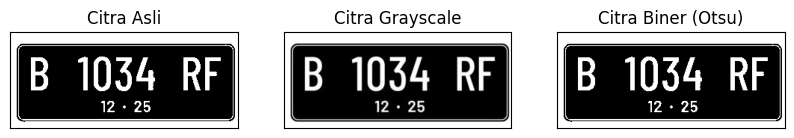

In [4]:
plat_no = cv2.imread("/content/drive/MyDrive/PCVK/Images/plat_nomer.jpg")

grey_plat = cv2.cvtColor(plat_no, cv2.COLOR_BGR2GRAY)

ref, plat_no = cv2.threshold(grey_plat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(10,10))

plt.subplot(131)
plt.imshow(cv2.cvtColor(plat_no, cv2.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(grey_plat, cmap='gray')
plt.title('Citra Grayscale')
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(plat_no, cmap='gray')
plt.title('Citra Biner (Otsu)')
plt.xticks([])
plt.yticks([])

plt.show()

### **2. GAMBAR NOISY TEXT**

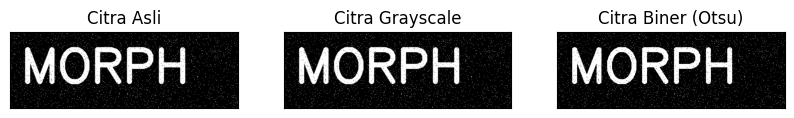

In [5]:
img_noisy = cv2.imread("/content/drive/MyDrive/PCVK/Images/noisy_text.png")

grey_noisy = cv2.cvtColor(img_noisy, cv2.COLOR_BGR2GRAY)

ref, noisy_text = cv2.threshold(grey_noisy, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(10,10))

plt.subplot(131)
plt.imshow(cv2.cvtColor(img_noisy, cv2.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(grey_noisy, cmap='gray')
plt.title('Citra Grayscale')
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(noisy_text, cmap='gray')
plt.title('Citra Biner (Otsu)')
plt.xticks([])
plt.yticks([])

plt.show()

## **PRAKTIKUM MORFOLOGI**
### 3. **Fungsi Dilasi**

<Figure size 1000x1000 with 0 Axes>

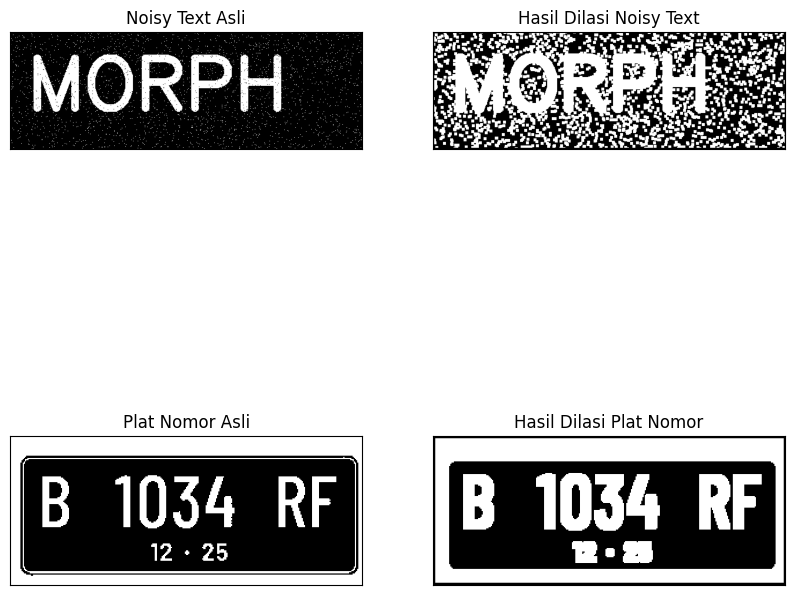

In [13]:
import numpy as np

def dilasi_citra(F,w):
  #size image
  p,q = F.shape

  imgD = np.zeros((p,q),dtype = np.uint8)

  SED = np.ones ((w,w),dtype=np.uint8)
  constant1 = (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

dilasi_noisy = dilasi_citra(img_noisy_text,5)
dilasi_plat = dilasi_citra(img_plat_no,5)

plt.figure(figsize=(10,10))

#Menampilkan 4 gambar Citra asli dan Dilasi
plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(dilasi_noisy, cmap='gray')
plt.title('Hasil Dilasi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(dilasi_plat, cmap='gray')
plt.title('Hasil Dilasi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()


### **4. Implementasi Dilasi OpenCV**

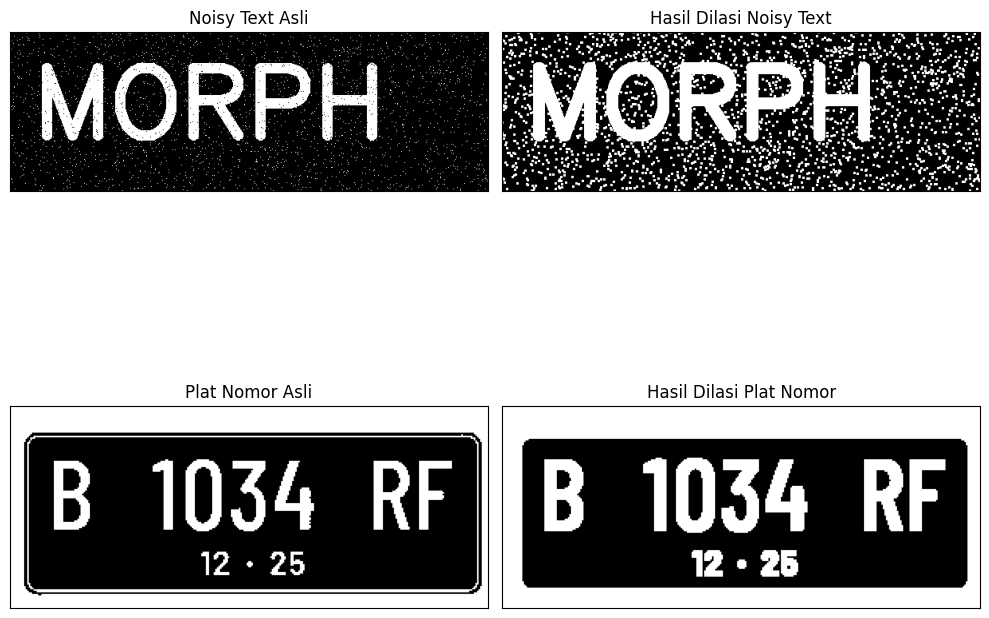

In [12]:
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

kernel = np.ones((3, 3), np.uint16)

dilasi_noisy = cv2.dilate(img_noisy_text, kernel, iterations=1)
dilasi_plat = cv2.dilate(img_plat_no, kernel, iterations=1)

plt.figure(figsize=(10,10))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(dilasi_noisy, cmap='gray')
plt.title('Hasil Dilasi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(dilasi_plat, cmap='gray')
plt.title('Hasil Dilasi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **5. Fungsi Erosi**

<Figure size 1000x1000 with 0 Axes>

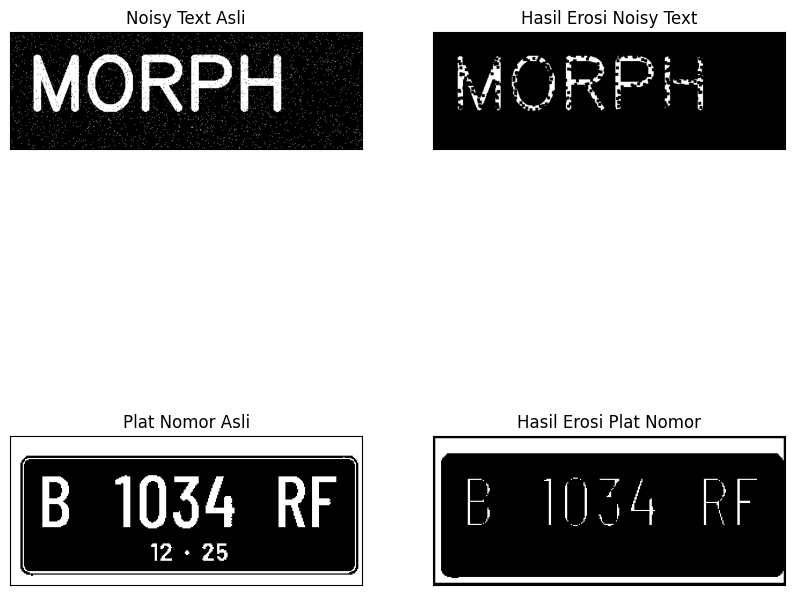

In [16]:
def erosi_citra(F,w):
  #size image
  m,n = F.shape

  SE = np.ones((w,w),dtype=np.uint8)
  constant2 = (w-1)//2
  imgE = np.zeros((m,n),dtype=np.uint8)

  #proses erosi
  for i in range(constant2, m-constant2):
    for j in range(constant2,n-constant2):
      temp= F[i-constant2:i+constant2+1, j-constant2:j+constant2+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE

img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

erosi_noisy = erosi_citra(img_noisy_text,5)
erosi_plat = erosi_citra(img_plat_no,5)

plt.figure(figsize=(10,10))

#Menampilkan 4 gambar Citra asli dan Erosi
plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(erosi_noisy, cmap='gray')
plt.title('Hasil Erosi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(erosi_plat, cmap='gray')
plt.title('Hasil Erosi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()

### **6. Implementasi Erosi OpenCV**

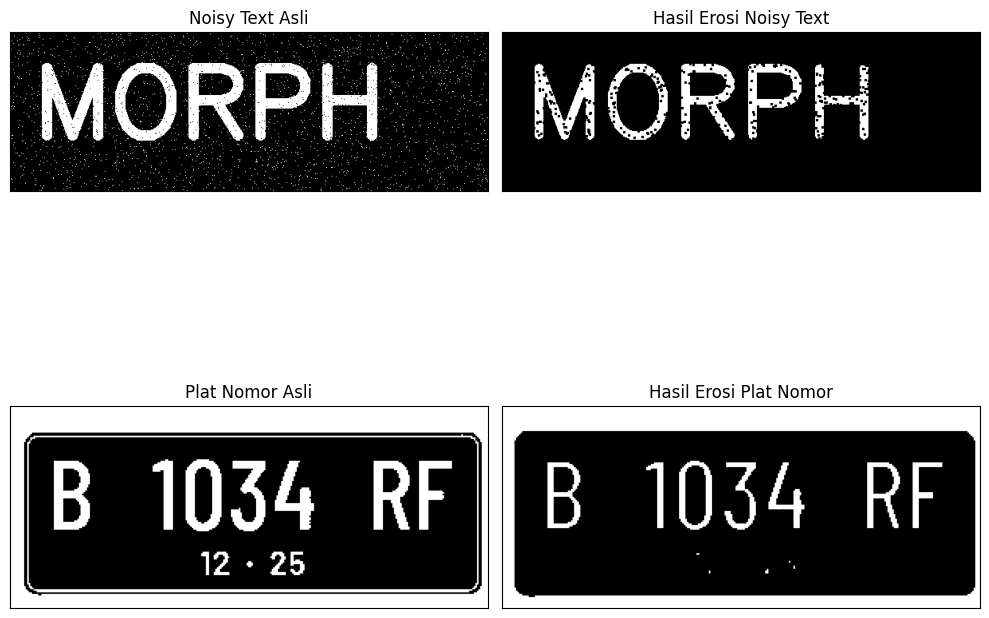

In [17]:
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

kernel = np.ones((3, 3), np.uint16)

erosi_noisy = cv2.erode(img_noisy_text, kernel, iterations=1)
erosi_plat = cv2.erode(img_plat_no, kernel, iterations=1)

plt.figure(figsize=(10,10))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(erosi_noisy, cmap='gray')
plt.title('Hasil Erosi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(erosi_plat, cmap='gray')
plt.title('Hasil Erosi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **7. Operasi Opening**
- Tanpa Library

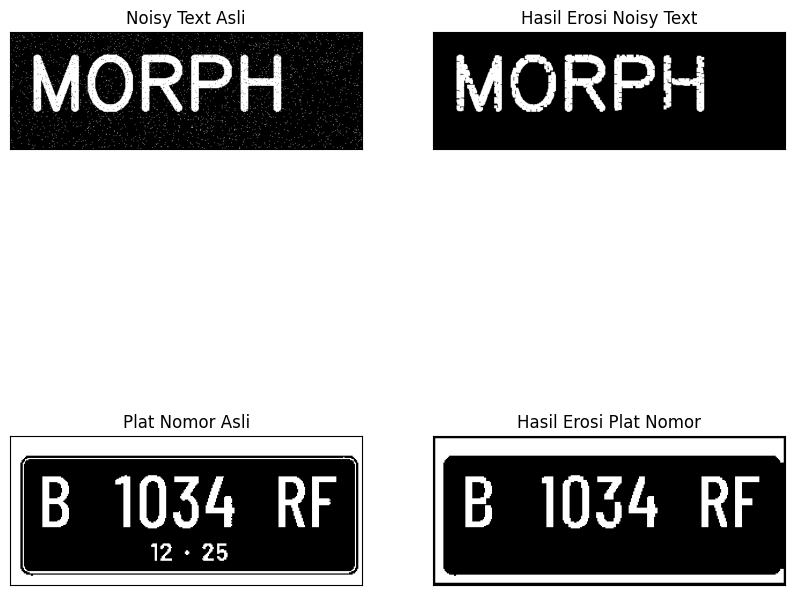

In [18]:
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

erosi_noisy = erosi_citra(img_noisy_text,5)
dilasi_noisy = dilasi_citra(erosi_noisy,5)

erosi_plat = erosi_citra(img_plat_no,5)
dilasi_plat = dilasi_citra(erosi_plat,5)

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(dilasi_noisy, cmap='gray')
plt.title('Hasil Erosi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(dilasi_plat, cmap='gray')
plt.title('Hasil Erosi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()

- Menggunakan Library Morphology

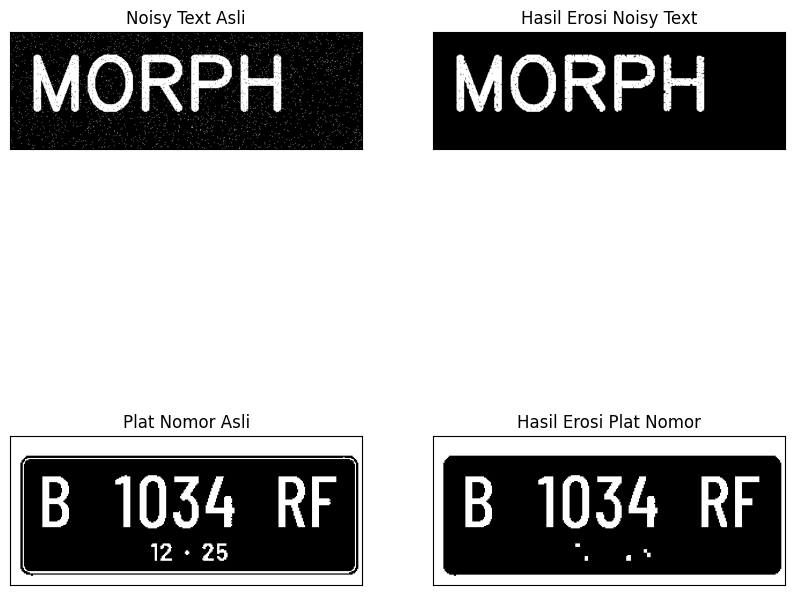

In [19]:
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

kernel = np.ones((3, 3), np.uint16)

opening_noisy = cv2.morphologyEx(img_noisy_text, cv2.MORPH_OPEN, kernel)
opening_plat = cv2.morphologyEx(img_plat_no, cv2.MORPH_OPEN,kernel)

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(opening_noisy, cmap='gray')
plt.title('Hasil Erosi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(opening_plat, cmap='gray')
plt.title('Hasil Erosi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()

### **8. Operasi Closing**
- Tanpa library

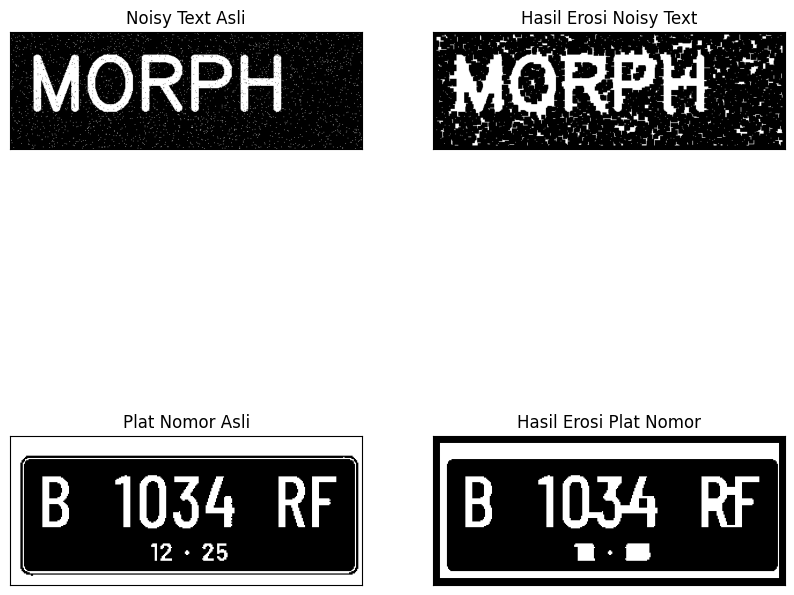

In [20]:
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

closing_noisy = erosi_citra(dilasi_citra(img_noisy_text,7),7)
closing_plat = erosi_citra(dilasi_citra(img_plat_no,7),7)

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(closing_noisy, cmap='gray')
plt.title('Hasil Erosi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(closing_plat, cmap='gray')
plt.title('Hasil Erosi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()

- Menggunakan Library Morphology

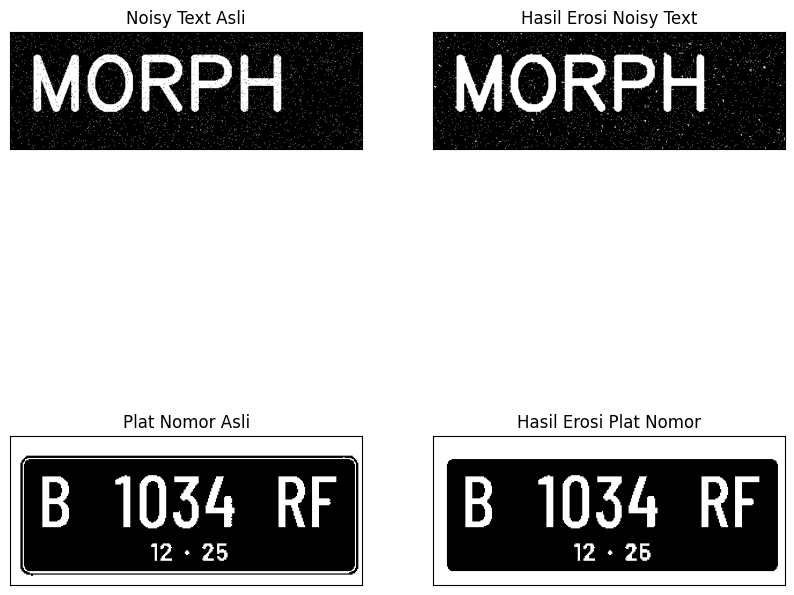

In [23]:
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

kernel = np.ones((3, 3), np.uint8)

closing_noisy = cv2.morphologyEx(img_noisy_text, cv2.MORPH_CLOSE, kernel)
closing_plat = cv2.morphologyEx(img_plat_no, cv2.MORPH_CLOSE,kernel)

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(closing_noisy, cmap='gray')
plt.title('Hasil Erosi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(closing_plat, cmap='gray')
plt.title('Hasil Erosi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()

### **9. Operasi Dilasi berbentuk Cross 3 x 3 dan 5 x 5**
- Cross 3x3


SED = CROSS 3


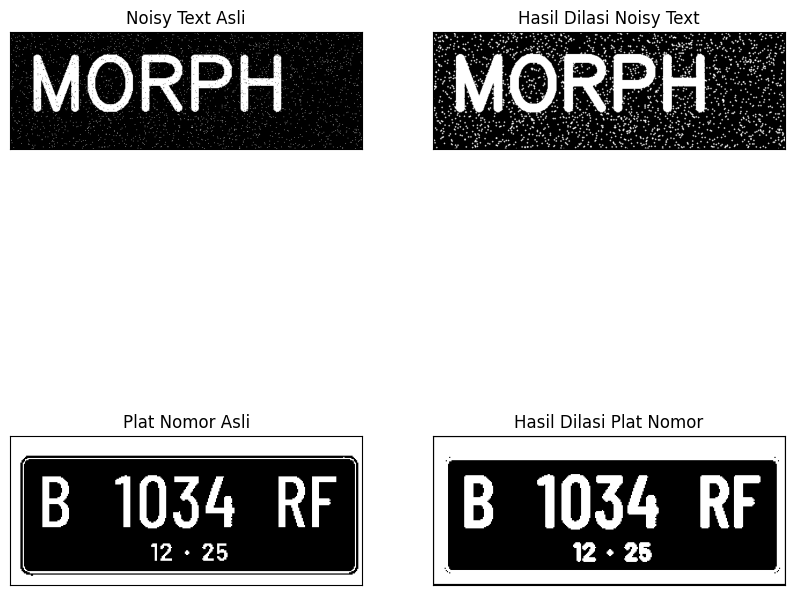

In [31]:
def dilasi_citra(F,w):
  p,q = F.shape

  imgD = np.zeros((p,q),dtype = np.uint8)

  SED = np.array([[0, 1, 0],
                  [1, 1, 1],
                  [0, 1, 0]], dtype = np.uint8)
  constant1 = (w-1)//2

  for i in range(constant1, p-constant1):
    for j in range(constant1, q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

print('SED = CROSS 3')
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

dilasi_noisy = dilasi_citra(img_noisy_text,3)
dilasi_plat = dilasi_citra(img_plat_no,3)

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(dilasi_noisy, cmap='gray')
plt.title('Hasil Dilasi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(dilasi_plat, cmap='gray')
plt.title('Hasil Dilasi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()

- Cross 5x5

SED = CROSS 5


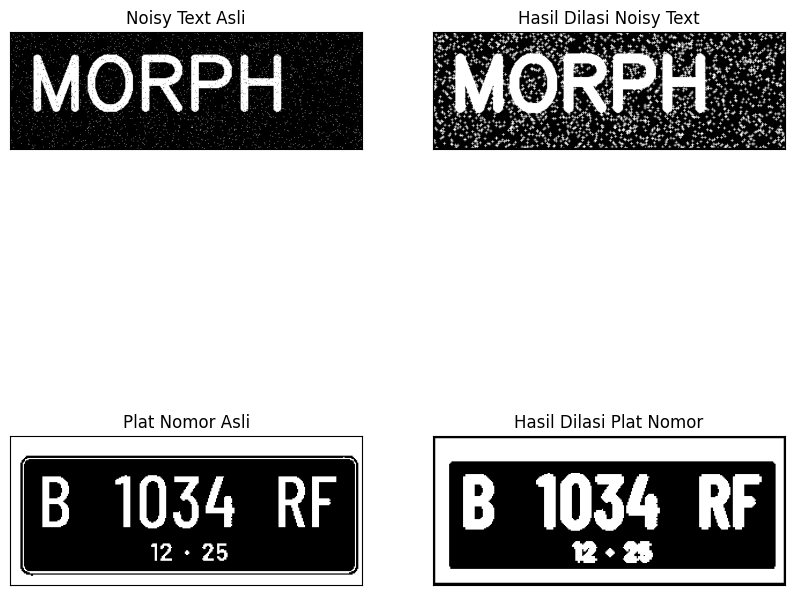

In [34]:
def dilasi_citra(F,w):
  p,q = F.shape

  imgD = np.zeros((p,q),dtype = np.uint8)

  # Structuring Element berbentuk Cross 5x5 yang simetris
  SED = np.array([[0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0],
                  [1, 1, 1, 1, 1],
                  [0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0]], dtype = np.uint8)
  constant1 = (w-1)//2

  for i in range(constant1, p-constant1):
    for j in range(constant1, q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

# Memulihkan fungsi print bawaan dan memanggilnya dengan benar
import builtins
print = builtins.print
print('SED = CROSS 5')

img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

dilasi_noisy = dilasi_citra(img_noisy_text,5)
dilasi_plat = dilasi_citra(img_plat_no,5)

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(dilasi_noisy, cmap='gray')
plt.title('Hasil Dilasi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(dilasi_plat, cmap='gray')
plt.title('Hasil Dilasi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()

### **10. Operasi dilasi circular 3x3 dan 5x5**
- dilasi circular 3x3

SED = CIRCULAR 3


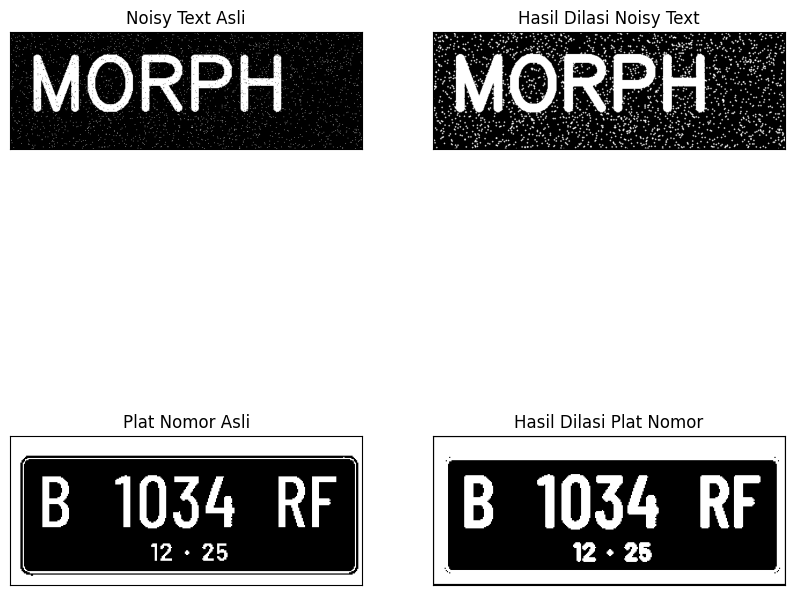

In [35]:
def dilasi_citra(F,w):
  p,q = F.shape

  imgD = np.zeros((p,q),dtype = np.uint8)

  SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
  constant1 = (w-1)//2

  for i in range(constant1, p-constant1):
    for j in range(constant1, q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

print('SED = CIRCULAR 3')
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

dilasi_noisy = dilasi_citra(img_noisy_text,3)
dilasi_plat = dilasi_citra(img_plat_no,3)

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(dilasi_noisy, cmap='gray')
plt.title('Hasil Dilasi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(dilasi_plat, cmap='gray')
plt.title('Hasil Dilasi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()

- dilasi circular 5x5

SED = CIRCULAR 5


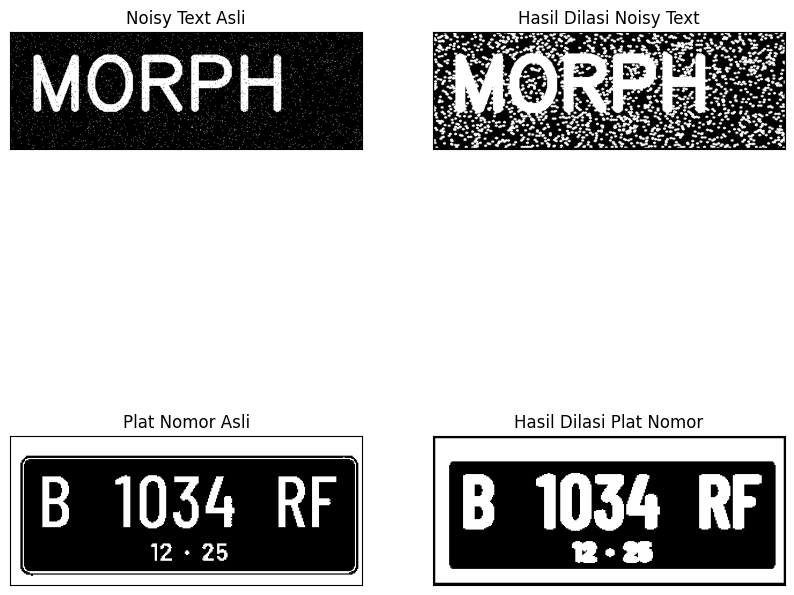

In [36]:
def dilasi_citra(F,w):
  p,q = F.shape

  imgD = np.zeros((p,q),dtype = np.uint8)

  SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
  constant1 = (w-1)//2

  for i in range(constant1, p-constant1):
    for j in range(constant1, q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

print('SED = CIRCULAR 5')
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

dilasi_noisy = dilasi_citra(img_noisy_text,5)
dilasi_plat = dilasi_citra(img_plat_no,5)

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(dilasi_noisy, cmap='gray')
plt.title('Hasil Dilasi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(dilasi_plat, cmap='gray')
plt.title('Hasil Dilasi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()

### **11. Operasi Erosi dengan Structuring Element Rectangle 3 x 5 dan 5 x 7**
- Erosi Rectangle 3x5 & 5x7

SE = RECTANGLE 3x5
SE = RECTANGLE 5x7


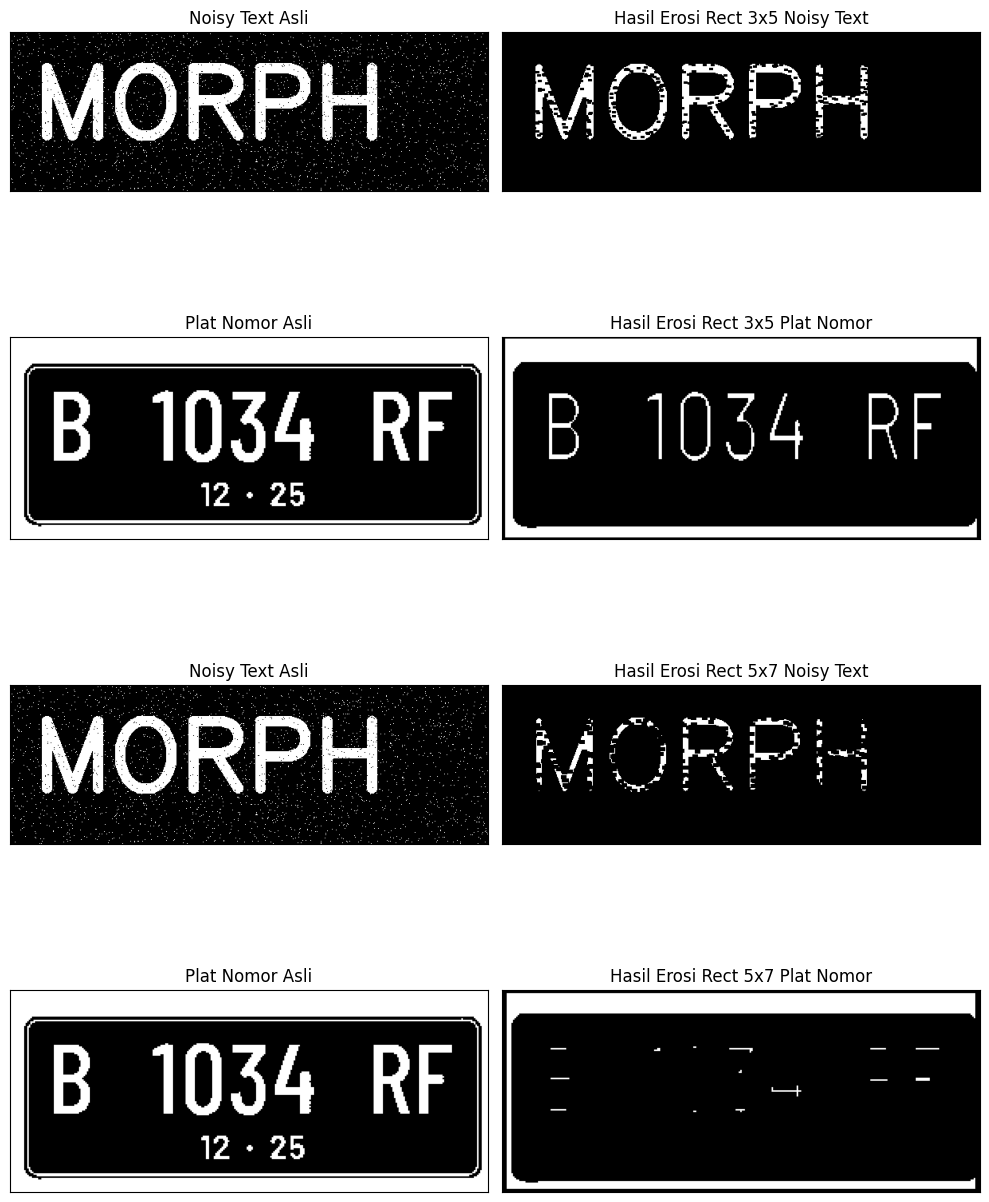

In [48]:
def erosi_rectangle(F, p, l):
  m, n = F.shape

  # Sesuaikan urutan dimensi (lebar, tinggi) di OpenCV agar menghasilkan matriks berukuran (p, l) di NumPy
  SE = cv2.getStructuringElement(cv2.MORPH_RECT, (l, p))
  constant1 = (p-1)//2
  constant2 = (l-1)//2

  imgE = np.zeros((m, n), dtype=np.uint8)

  for i in range(constant1, m-constant1):
    for j in range(constant2, n-constant2):
      temp = F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product = temp * SE
      imgE[i, j] = np.min(product)

  return imgE

print('SE = RECTANGLE 3x5')
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

erosi_noisy = erosi_rectangle(img_noisy_text, 3, 5)
erosi_plat = erosi_rectangle(img_plat_no, 3, 5)

print('SE = RECTANGLE 5x7')
erosi_noisy_2 = erosi_rectangle(img_noisy_text, 5, 7)
erosi_plat_2 = erosi_rectangle(img_plat_no, 5, 7)

# Menggunakan grid 4x2 agar dapat menampung seluruh 8 subplot
plt.figure(figsize=(10, 14))

# Baris 1: Erosi Rect 3x5 (Noisy Text)
plt.subplot(4, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(4, 2, 2)
plt.imshow(erosi_noisy, cmap='gray')
plt.title('Hasil Erosi Rect 3x5 Noisy Text')
plt.xticks([])
plt.yticks([])

# Baris 2: Erosi Rect 3x5 (Plat Nomor)
plt.subplot(4, 2, 3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(4, 2, 4)
plt.imshow(erosi_plat, cmap='gray')
plt.title('Hasil Erosi Rect 3x5 Plat Nomor')
plt.xticks([])
plt.yticks([])

# Baris 3: Erosi Rect 5x7 (Noisy Text)
plt.subplot(4, 2, 5)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(4, 2, 6)
plt.imshow(erosi_noisy_2, cmap='gray')
plt.title('Hasil Erosi Rect 5x7 Noisy Text')
plt.xticks([])
plt.yticks([])

# Baris 4: Erosi Rect 5x7 (Plat Nomor)
plt.subplot(4, 2, 7)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(4, 2, 8)
plt.imshow(erosi_plat_2, cmap='gray')
plt.title('Hasil Erosi Rect 5x7 Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **12. Erosi Line Vertikal 3 & 5**

SE = LINE VERTIKAL 3
SE = LINE VERTIKAL 5


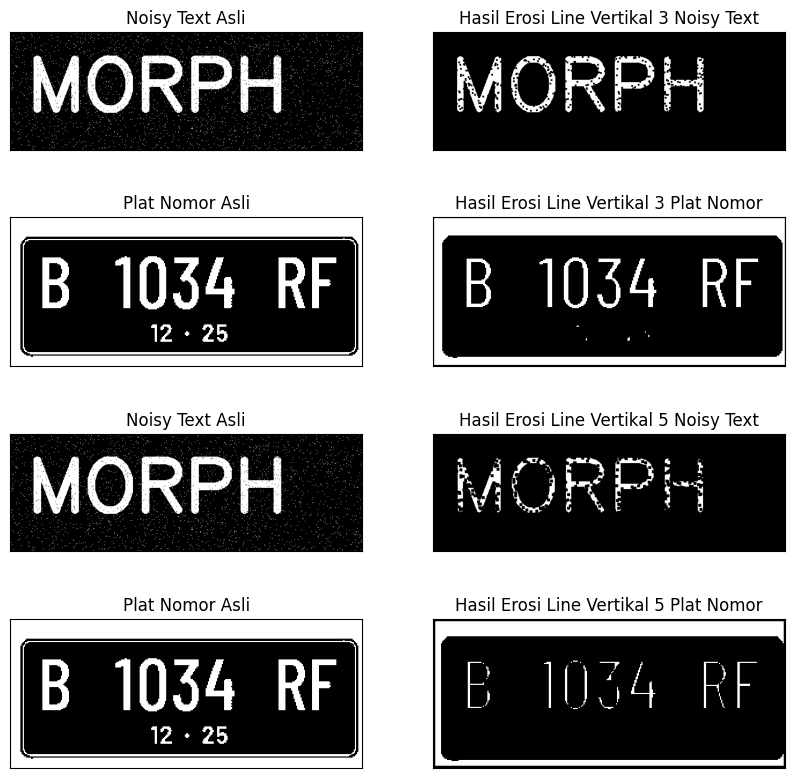

In [49]:
def erosi_citra(F,k):
  m,n = F.shape

  # Sesuaikan urutan dimensi (lebar, tinggi) di OpenCV agar menghasilkan matriks berukuran (p, l) di NumPy
  SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k))
  constant1 = (k-1)//2

  imgE = np.zeros((m,n),dtype = np.uint8)

  for i in range(constant1, m-constant1):
    for j in range(constant1, n-constant1):
      temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product = temp * SE
      imgE[i,j] = np.min(product)

  return imgE

print('SE = LINE VERTIKAL 3')
img_noisy_text = noisy_text.copy()
img_plat_no = plat_no.copy()

erosi_noisy = erosi_citra(img_noisy_text,3)
erosi_plat = erosi_citra(img_plat_no,3)

print('SE = LINE VERTIKAL 5')
erosi_noisy_2 = erosi_citra(img_noisy_text,5)
erosi_plat_2 = erosi_citra(img_plat_no,5)

plt.figure(figsize=(10,10))
plt.subplot(4,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(4,2,2)
plt.imshow(erosi_noisy, cmap='gray')
plt.title('Hasil Erosi Line Vertikal 3 Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(4,2,3)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(4,2,4)
plt.imshow(erosi_plat, cmap='gray')
plt.title('Hasil Erosi Line Vertikal 3 Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.subplot(4,2,5)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(4,2,6)
plt.imshow(erosi_noisy_2, cmap='gray')
plt.title('Hasil Erosi Line Vertikal 5 Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(4,2,7)
plt.imshow(img_plat_no, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(4,2,8)
plt.imshow(erosi_plat_2, cmap='gray')
plt.title('Hasil Erosi Line Vertikal 5 Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()

### **13. Transformasi TOP-HAT element 3x3**

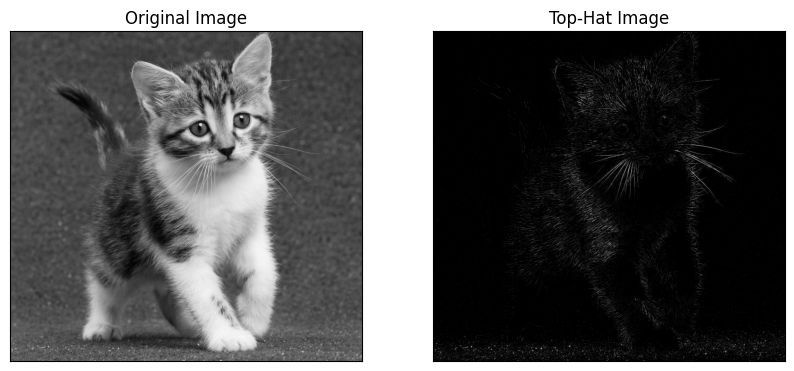

In [50]:
filtersize = (3,3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filtersize)

img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01 (1).jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(10,10))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.xticks([])
plt.yticks([])

plt.subplot(1,2,2)
plt.imshow(tophat_img, cmap='gray')
plt.title('Top-Hat Image')
plt.xticks([])
plt.yticks([])

plt.show()

### **14. Transformasi Black-Hat element 3x3**

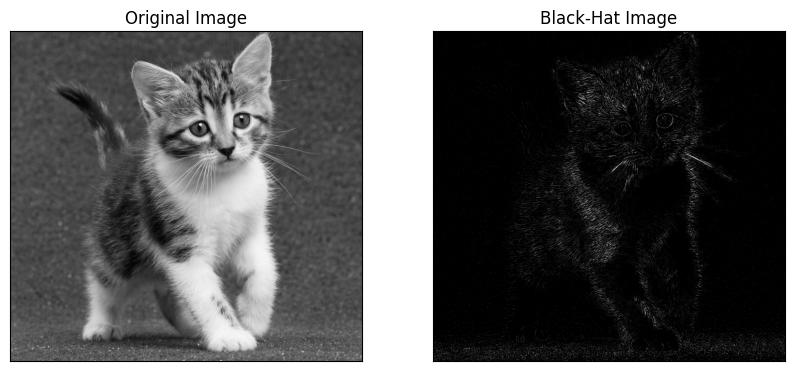

In [51]:
kitten = img.copy()
filtersize = (3,3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filtersize)

blackhat_img = cv2.morphologyEx(kitten, cv2.MORPH_BLACKHAT,kernel)

plt.figure(figsize=(10,10))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.xticks([])
plt.yticks([])

plt.subplot(1,2,2)
plt.imshow(blackhat_img, cmap='gray')
plt.title('Black-Hat Image')
plt.xticks([])
plt.yticks([])

plt.show()

### **15. Program skeleton pada citra biner**

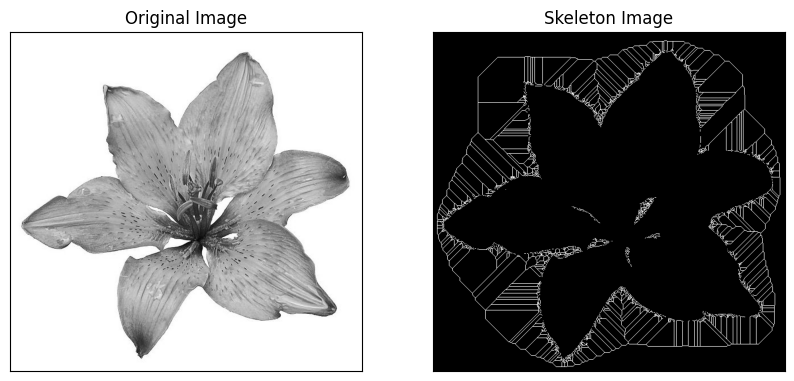

In [59]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Read image in grayscale mode
lily_img = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg', cv.IMREAD_GRAYSCALE)

binary = lily_img > filters.threshold_triangle(lily_img)

binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(10,10))
plt.subplot(1,2,1)
plt.imshow(lily_img, cmap='gray')
plt.title('Original Image')
plt.xticks([])
plt.yticks([])

plt.subplot(1,2,2)
plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image')
plt.xticks([])
plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()

### **16. Program skeleton pada citra hasil inverse**

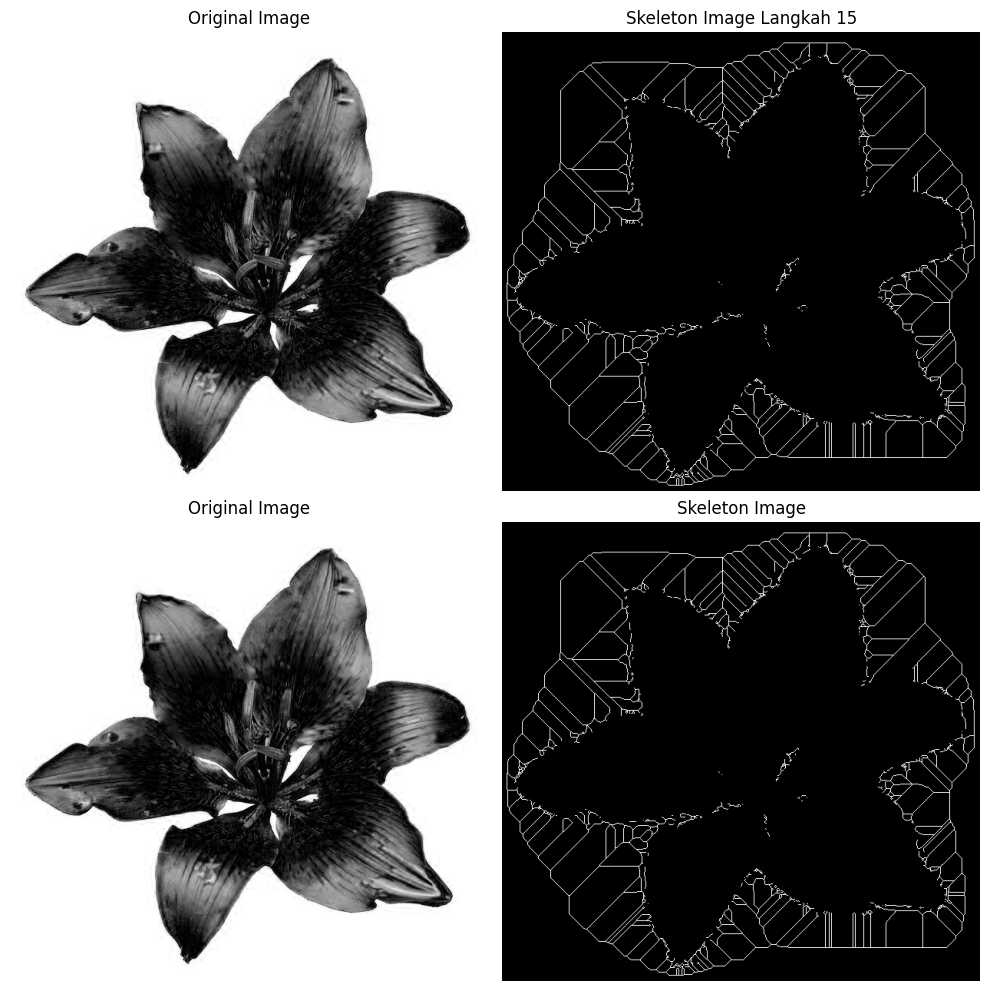

In [64]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize
import cv2 as cv

img = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')[...,0]
img1 = skeleton.copy()

binary = img > filters.threshold_triangle(img)

skeleton1 = skeletonize(binary)

# Create a 2x2 subplot grid to accommodate 4 images
fig, ax = plt.subplots(2, 2, figsize=(10, 10))

ax[0, 0].imshow(img, cmap='gray')
ax[0, 0].set_title('Original Image')
ax[0, 0].axis('off')

ax[0, 1].imshow(img1, cmap='gray')
ax[0, 1].set_title('Skeleton Image Langkah 15')
ax[0, 1].axis('off')

ax[1, 0].imshow(img, cmap='gray')
ax[1, 0].set_title('Original Image')
ax[1, 0].axis('off')

ax[1, 1].imshow(skeleton1, cmap='gray')
ax[1, 1].set_title('Skeleton Image')
ax[1, 1].axis('off')

plt.tight_layout()
plt.show()

### **17. Program thinning memakai morphology.thin()**


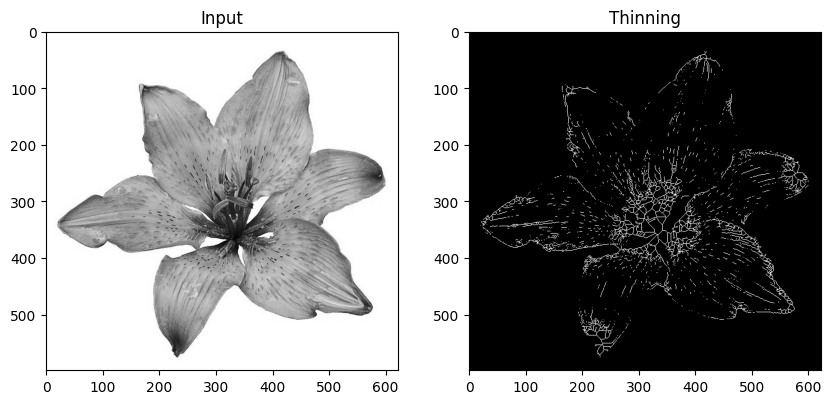

In [65]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt
image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')))
image_binary = image < 0.5

out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f,(ax0, ax1) = plt.subplots(1,2, figsize=(10, 10))
ax0.imshow(image,cmap = 'gray')
ax0.set_title('Input')

ax1.imshow(out_thin,cmap = 'gray')
ax1.set_title('Thinning')

plt.savefig("thinning.png")
plt.show()